# One Way ANOVA code

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols

In [11]:
df = sns.load_dataset("iris")

In [12]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


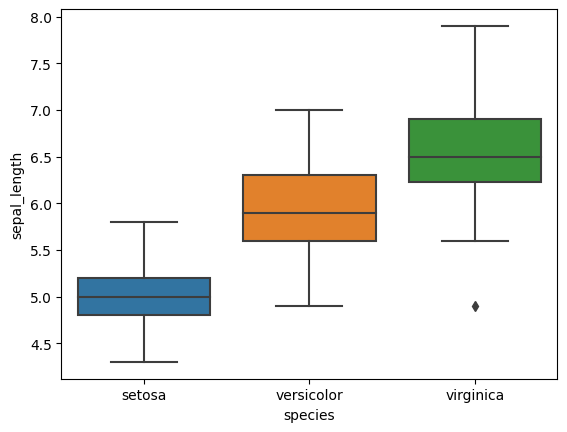

In [13]:
sns.boxplot(x="species",y="sepal_length",data=df)
plt.show()

- The boxplot shows that the sepal length varies significantly for all three species, they all have a different spread and different median. We can do ANOVA analysis to find if they differ significantly and than we can do post-hoc analysis t determine the pair of species that differe significantly as ANOVA only tells there is a diference bur does not tell which two groups differ

In [14]:
# fitting an ols model
model = ols('sepal_length ~ species',data=df).fit()

- In the context of the ANOVA test in statsmodels.stats.anova.anova_lm, Type 1, Type 2, and Type 3 refer to different methods for partitioning the sums of squares and determining the contribution of each variable or term to the overall variation in the response variable.

- Type 1 sums of squares measure the unique contribution of each variable in the model, after accounting for the effects of all the previous variables. This method is appropriate when the order of the variables in the model is fixed and meaningful, such as in a designed experiment where the variables are manipulated in a specific order.

- Type 2 sums of squares measure the unique contribution of each variable in the model, without regard for the order in which the variables were entered into the model. This method is appropriate when the variables in the model are not manipulated in a specific order, or when there is a priori knowledge about which variables are most important.

- Type 3 sums of squares measure the unique contribution of each variable in the model, after accounting for the effects of all the other variables, including any interaction terms. This method is appropriate when the variables in the model are not orthogonal, or when there is a high degree of collinearity among the variables.

- The choice of which type of sums of squares to use depends on the specific research question and the design of the experiment or observational study. In general, Type 3 sums of squares are preferred when there are interactions or collinearity among the variables, while Type 1 or Type 2 sums of squares may be more appropriate for simpler designs.

In [15]:
# calculating anova table using the model
anova_table = sm.stats.anova_lm(model,type=2)

In [16]:
# showing the anova table
anova_table

,df,sum_sq,mean_sq,F,PR(>F)
species,2.0,63.212133,31.606067,119.264502,1.669669e-31
Residual,147.0,38.956200,0.265008,NaN,NaN


,df,sum_sq,mean_sq,F,PR(>F)
species,2.0,63.212133,31.606067,119.264502,1.669669e-31
Residual,147.0,38.956200,0.265008,NaN,NaN


- The table show that the p-valus is less than 0.05 so we will furthe move to post-hoc analysis

In [17]:
# doing a pairwise t-test on the model using sidak method
pairwise_ttest = model.t_test_pairwise("species", method="sidak")

In [20]:
pairwise_ttest.result_frame

,coef,std err,t,P>|t|,Conf. Int. Low,Conf. Int. Upp.,pvalue-sidak,reject-sidak
versicolor-setosa,0.930,0.102958,9.032819,8.770194e-16,0.726531,1.133469,2.631058e-15,True
virginica-setosa,1.582,0.102958,15.365506,2.214821e-32,1.378531,1.785469,6.644464e-32,True
virginica-versicolor,0.652,0.102958,6.332686,2.765638e-09,0.448531,0.855469,8.296915e-09,True


- The above dataframe is showing results for pairwise t-test. The p-value for all t-test is less than 0.05 and the last column tells us to reject the null hypothesis for all three t-test. So, each specie mean significantly differs from the other specie

In [22]:
# doing a pairwise t-test on the model using bonferroni method
pairwise_ttest_bon = model.t_test_pairwise("species", method="bonferroni")

In [24]:
# doing a pairwise t-test on the model using bonferroni method
pairwise_ttest_bon.result_frame

,coef,std err,t,P>|t|,Conf. Int. Low,Conf. Int. Upp.,pvalue-bonferroni,reject-bonferroni
versicolor-setosa,0.930,0.102958,9.032819,8.770194e-16,0.726531,1.133469,2.631058e-15,True
virginica-setosa,1.582,0.102958,15.365506,2.214821e-32,1.378531,1.785469,6.644464e-32,True
virginica-versicolor,0.652,0.102958,6.332686,2.765638e-09,0.448531,0.855469,8.296915e-09,True


# Performing Tukey tes


In [28]:
# installing a library
!pip install pingouin

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 198.6/198.6 KB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for littleutils: filename=littleutils-0.2.2-py3-none-any.whl size=7048 sha256=e03fdb9a4a5ea67814199c919924ec32f920e518a8a56ef8392af7c920a2e294
  Stored in directory: /root/.cache/pip/wheels/04/bb/0d/2d02ec45f29c48d6192476bfb59c5a0e64b605e7212374dd15
Successfully built littleutils


In [29]:
import pingouin as pg

In [32]:
# dv, means numerical variable to study
# between, categorical variable among which to study the numerical variable
# detailed, to et detailed result
anova = pg.anova(df,dv="sepal_length",between="species",detailed=True)

In [33]:
# checking result
anova

,Source,SS,DF,MS,F,p-unc,np2
0,species,63.212133,2,31.606067,119.264502,1.669669e-31,0.618706
1,Within,38.956200,147,0.265008,NaN,NaN,NaN


- The p-value is less than 0.05, we will do post hoc analysis using tuckey hsd test

In [34]:
# tikey hsd
tukey = pg.pairwise_tukey(df,dv="sepal_length",between="species")

In [35]:
tukey

,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,setosa,versicolor,5.006,5.936,-0.930,0.102958,-9.032819,2.420286e-14,-2.088053
1,setosa,virginica,5.006,6.588,-1.582,0.102958,-15.365506,2.153833e-14,-3.053629
2,versicolor,virginica,5.936,6.588,-0.652,0.102958,-6.332686,8.287554e-09,-1.117195


- The p-value given for each pairwise test is less than 0.05, so each group mean significantly differs from the others